<a href="https://colab.research.google.com/github/guruprasathr1996-cyber/Amazon_Product_Review/blob/main/Amazon_Product_review.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import os
import tensorflow as tf

from google.colab import files

uploaded = files.upload()

# Find the uploaded CSV file
csv_files = [f for f in uploaded.keys() if f.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Please upload the dataset CSV file.")

df = pd.read_csv(csv_files[0])

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())
print("\nMissing values:")
print(df.isnull().sum())

Saving amazon.csv to amazon.csv
Dataset shape: (1465, 16)

Columns:
['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link']


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...



Missing values:
product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           2
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64


In [5]:
# Remove spaces from column names
df.columns = df.columns.str.strip()

# Check required columns
required = [
    "product_name", "category", "discounted_price",
    "actual_price", "discount_percentage", "rating",
    "about_product", "review_title", "review_content"
]

missing_columns = [c for c in required if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Remove duplicate complete rows
df = df.drop_duplicates().copy()

# Convert currency, percentage, and rating columns to numbers
def clean_number(value):
    if pd.isna(value):
        return np.nan
    value = str(value).replace(",", "").replace("₹", "").strip()
    value = re.sub(r"[^0-9.\-]", "", value)
    try:
        return float(value)
    except ValueError:
        return np.nan

df["rating"] = df["rating"].apply(clean_number)
df["discounted_price"] = df["discounted_price"].apply(clean_number)
df["actual_price"] = df["actual_price"].apply(clean_number)
df["discount_percentage"] = df["discount_percentage"].apply(clean_number)

# Keep valid ratings between 1 and 5
df = df[df["rating"].between(1, 5)].copy()

# Replace missing product information
text_columns = [
    "product_name", "category", "about_product",
    "review_title", "review_content"
]

for col in text_columns:
    df[col] = df[col].fillna("").astype(str)

# Create a combined text field
df["review_text"] = (
    df["review_title"] + " " +
    df["review_content"] + " " +
    df["product_name"] + " " +
    df["about_product"]
).str.strip()

# Fill missing numeric features using medians
numeric_columns = [
    "discounted_price", "actual_price", "discount_percentage"
]

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# Fill numeric columns if an entire column was missing
df[numeric_columns] = df[numeric_columns].fillna(0)

# Keep rows with meaningful text
df = df[df["review_text"].str.strip().ne("")].copy()
df = df.reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("\nMissing values after cleaning:")
print(df[required].isnull().sum())
display(df[["review_text", "rating"]].head())

Cleaned dataset shape: (1464, 17)

Missing values after cleaning:
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
about_product          0
review_title           0
review_content         0
dtype: int64


,review_text,rating
0,"Satisfied,Charging is really fast,Value for mo...",4.2
1,"A Good Braided Cable for Your Type C Device,Go...",4.0
2,"Good speed for earlier versions,Good Product,W...",3.9
3,"Good product,Good one,Nice,Really nice product...",4.2
4,"As good as original,Decent,Good one for second...",4.2


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Input features and target
X_text = df["review_text"].values
X_category = df["category"].values
X_numeric = df[numeric_columns].values.astype("float32")
y = df["rating"].values.astype("float32")

# Split before fitting preprocessing tools
indices = np.arange(len(df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42
)

X_text_train = X_text[train_idx]
X_text_test = X_text[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

# Tokenize using training text only
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 10000
MAX_LEN = 150

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_text_train)

X_train_seq = pad_sequences(
    tokenizer.texts_to_sequences(X_text_train),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_seq = pad_sequences(
    tokenizer.texts_to_sequences(X_text_test),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

# Encode categories without using the target
X_train_cat = pd.get_dummies(
    pd.Series(X_category[train_idx]),
    dtype=float
)
X_test_cat = pd.get_dummies(
    pd.Series(X_category[test_idx]),
    dtype=float
)

# Ensure test columns match training columns
X_test_cat = X_test_cat.reindex(
    columns=X_train_cat.columns,
    fill_value=0
)

X_train_cat = X_train_cat.values.astype("float32")
X_test_cat = X_test_cat.values.astype("float32")

# Standardize numeric features using training data only
scaler = StandardScaler()

X_train_num = scaler.fit_transform(
    X_numeric[train_idx]
).astype("float32")

X_test_num = scaler.transform(
    X_numeric[test_idx]
).astype("float32")

# Combine numeric and category features
X_train_product = np.concatenate(
    [X_train_cat, X_train_num], axis=1
)

X_test_product = np.concatenate(
    [X_test_cat, X_test_num], axis=1
)

print("Training samples:", len(y_train))
print("Testing samples:", len(y_test))
print("Vocabulary size:", min(MAX_WORDS, len(tokenizer.word_index) + 1))
print("Product feature count:", X_train_product.shape[1])

Training samples: 1171
Testing samples: 293
Vocabulary size: 10000
Product feature count: 199


In [7]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Dense,
    Dropout, Concatenate, BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping

# Text input branch
text_input = Input(
    shape=(MAX_LEN,),
    name="review_input"
)

x = Embedding(
    input_dim=MAX_WORDS,
    output_dim=64,
    mask_zero=True
)(text_input)

x = LSTM(32)(x)
x = Dropout(0.3)(x)

# Product feature input branch
product_input = Input(
    shape=(X_train_product.shape[1],),
    name="product_input"
)

p = Dense(32, activation="relu")(product_input)
p = BatchNormalization()(p)
p = Dropout(0.2)(p)

# Combine text and product features
combined = Concatenate()([x, p])
combined = Dense(32, activation="relu")(combined)
combined = Dropout(0.2)(combined)

# Predict a numerical rating
output = Dense(1, activation="linear")(combined)

model = Model(
    inputs=[text_input, product_input],
    outputs=output
)

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = model.fit(
    {
        "review_input": X_train_seq,
        "product_input": X_train_product
    },
    y_train,
    validation_split=0.20,
    epochs=30,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ review_input        │ (None, 150)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ product_input       │ (None, 199)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 150, 64)   │    640,000 │ review_input[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 150)       │          0 │ review_input[0][… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      6,400 │ product_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 32)        │     12,416 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32)        │        128 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64)        │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 32)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         33 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 661,057 (2.52 MB)

 Trainable params: 660,993 (2.52 MB)

 Non-trainable params: 64 (256.00 B)

Epoch 1/30
59/59 ━━━━━━━━━━━━━━━━━━━━ 13s 81ms/step - loss: 6.8189 - mae: 2.1625 - val_loss: 0.3713 - val_mae: 0.5501
Epoch 2/30
59/59 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - loss: 1.1494 - mae: 0.8513 - val_loss: 0.2498 - val_mae: 0.4343
Epoch 3/30
59/59 ━━━━━━━━━━━━━━━━━━━━ 6s 96ms/step - loss: 0.9227 - mae: 0.7727 - val_loss: 0.4449 - val_mae: 0.6183
Epoch 4/30
59/59 ━━━━━━━━━━━━━━━━━━━━ 9s 81ms/step - loss: 0.8582 - mae: 0.7339 - val_loss: 0.2532 - val_mae: 0.4487
Epoch 5/30
59/59 ━━━━━━━━━━━━━━━━━━━━ 5s 83ms/step - loss: 0.7972 - mae: 0.7133 - val_loss: 0.2258 - val_mae: 0.4196
Epoch 6/30
59/59 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - loss: 0.6661 - mae: 0.6529 - val_loss: 0.1949 - val_mae: 0.3912
Epoch 7/30
59/59 ━━━━━━━━━━━━━━━━━━━━ 6s 99ms/step - loss: 0.6832 - mae: 0.6484 - val_loss: 0.1334 - val_mae: 0.3114
Epoch 8/30
59/59 ━━━━━━━━━━━━━━━━━━━━ 9s 78ms/step - loss: 0.6969 - mae: 0.6617 - val_loss: 0.2728 - val_mae: 0.4721
Epoch 9/30
59/59 ━━━━━━━━━━━━━━━━━━━━ 6s 97ms/step - loss: 0.69

In [8]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict test ratings
y_pred = model.predict(
    {
        "review_input": X_test_seq,
        "product_input": X_test_product
    },
    verbose=0
).flatten()

# Ratings should be between 1 and 5
y_pred = np.clip(y_pred, 1, 5)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("----------------")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")

MODEL EVALUATION
----------------
MAE  : 0.2120
RMSE : 0.2748
R2   : 0.0268


,Actual Rating,Predicted Rating,Absolute Error
0,4.2,4.09,0.11
1,3.7,3.90,0.20
2,3.3,3.78,0.48
3,4.3,4.13,0.17
4,3.9,4.25,0.35
5,4.5,3.90,0.60
6,4.1,4.32,0.22
7,4.1,3.86,0.24
8,4.2,4.09,0.11
9,3.6,3.74,0.14


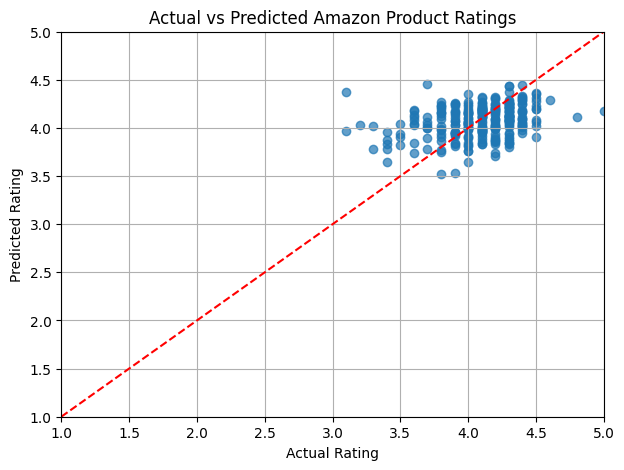

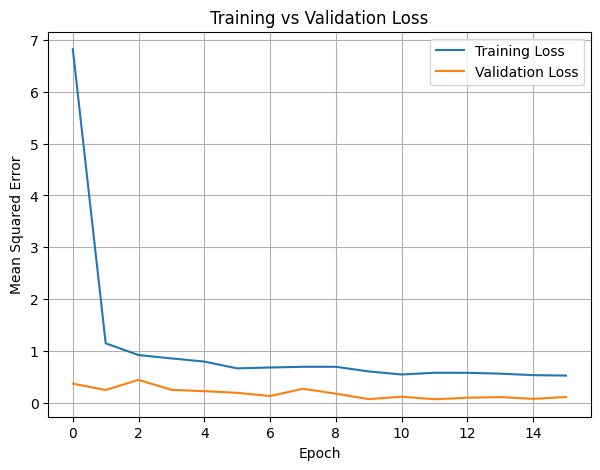

In [9]:
comparison = pd.DataFrame({
    "Actual Rating": y_test,
    "Predicted Rating": np.round(y_pred, 2),
    "Absolute Error": np.round(np.abs(y_test - y_pred), 2)
})

display(comparison.head(20))

# Plot actual versus predicted ratings
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot([1, 5], [1, 5], "r--")
plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Amazon Product Ratings")
plt.xlim(1, 5)
plt.ylim(1, 5)
plt.grid(True)
plt.show()

# Training and validation loss
plt.figure(figsize=(7, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
def predict_rating(
    review,
    product_name="",
    category=None,
    discounted_price=None,
    actual_price=None,
    discount_percentage=None,
    about_product=""
):
    # Prepare new review text
    text = (
        str(review) + " " +
        str(product_name) + " " +
        str(about_product)
    ).strip()

    # Convert text to a padded numerical sequence
    sequence = tokenizer.texts_to_sequences([text])
    sequence = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Encode product category using training columns
    if category is None:
        category = str(df["category"].mode().iloc[0])

    category_row = pd.get_dummies(
        pd.Series([str(category)]),
        dtype=float
    )

    category_row = category_row.reindex(
        columns=X_train_cat_columns if False else X_train_cat_names,
        fill_value=0
    ).values.astype("float32")

    # Use training-data medians for omitted numeric values
    defaults = df[numeric_columns].median()

    numeric_row = np.array([[
        defaults["discounted_price"]
        if discounted_price is None else clean_number(discounted_price),

        defaults["actual_price"]
        if actual_price is None else clean_number(actual_price),

        defaults["discount_percentage"]
        if discount_percentage is None else clean_number(discount_percentage)
    ]], dtype="float32")

    numeric_row = np.nan_to_num(numeric_row, nan=0.0)
    numeric_row = scaler.transform(numeric_row).astype("float32")

    product_row = np.concatenate(
        [category_row, numeric_row],
        axis=1
    )

    prediction = model.predict(
        {
            "review_input": sequence,
            "product_input": product_row
        },
        verbose=0
    )[0][0]

    prediction = float(np.clip(prediction, 1, 5))

    print("Customer Review:", review)
    print(f"Predicted Product Rating: {prediction:.2f} / 5")

    return prediction


# Save category feature names for inference
X_train_cat_names = list(
    pd.get_dummies(
        pd.Series(X_category[train_idx]),
        dtype=float
    ).columns
)

# Test on new, illustrative reviews
predict_rating(
    review="Excellent quality and very useful product. Worth the money.",
    product_name="Wireless Headphones",
    category="Electronics"
)

predict_rating(
    review="Poor quality. The product stopped working after two days.",
    product_name="Electronic Accessory",
    category="Electronics"
)

predict_rating(
    review="Good product, works as expected, but delivery was slow."
)

Customer Review: Excellent quality and very useful product. Worth the money.
Predicted Product Rating: 3.48 / 5
Customer Review: Poor quality. The product stopped working after two days.
Predicted Product Rating: 3.62 / 5
Customer Review: Good product, works as expected, but delivery was slow.
Predicted Product Rating: 2.95 / 5


2.9487476348876953

In [11]:
import pickle

model.save("amazon_rating_lstm.keras")

with open("amazon_tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

from google.colab import files

files.download("amazon_rating_lstm.keras")
files.download("amazon_tokenizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>